# Лабораторная работа №1
## Разработка генератора синтетических временных рядов на Python в Jupyter Notebook

**Выполнил: Голубенко Никита**

**Цель работы.** Получить практические навыки генерации синтетических временных рядов на языке Python. Реализуется генератор с фиксированным интервалом 5 минут, настройкой количества точек, режима дисперсии, тренда и сезонности, сохранением результата в CSV и визуализацией в PNG.

В работе выполнена основная часть задания и все дополнительные задания: нелинейные тренды, выбросы, пропуски и сохранение метаданных в JSON.

## 1. Импорт библиотек

Используются `numpy`, `matplotlib` и стандартные библиотеки Python. Библиотека `pandas` не используется.

In [9]:
import csv
import json
import random
from datetime import datetime, timedelta
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

ROOT = Path('.')
IMAGE_DIR = ROOT / 'images'
IMAGE_DIR.mkdir(exist_ok=True)

INTERVAL_MINUTES = 5
DEFAULT_POINTS = 1000
DEFAULT_START_VALUE = 100.0

VARIANCE_MODES = ('const', 'grow', 'decay', 'random')
TREND_MODES = ('none', 'fast_up', 'slow_up', 'fast_down', 'slow_down', 'random')
SEASONALITY_MODES = ('none', 'one', 'two', 'random')
NONLINEAR_TREND_MODES = ('none', 'exponential', 'polynomial', 'logarithmic')

print('Фиксированный шаг:', INTERVAL_MINUTES, 'минут')
print('Количество точек по умолчанию:', DEFAULT_POINTS)

Фиксированный шаг: 5 минут
Количество точек по умолчанию: 1000


## 2. Реализация генератора

Временная шкала начинается в `00:00:00` текущего дня, каждая следующая точка увеличивается на 5 минут.

Режимы основной части: дисперсия `const`, `grow`, `decay`, `random`; линейный тренд `none`, `fast_up`, `slow_up`, `fast_down`, `slow_down`, `random`; сезонность `none`, `one`, `two`, `random`.

Для сезонности используются периоды из задания: 12 точек (1 час) и 72 точки (6 часов).


На графиках дата и время отображаются в формате `ДД.ММ ЧЧ:ММ`, например `06.10 12:00`.

In [10]:
def _choose_mode(mode, allowed_modes, rng):
    if mode not in allowed_modes:
        raise ValueError(f'Недопустимый режим {mode!r}. Допустимые значения: {allowed_modes}')
    if mode == 'random':
        return rng.choice([m for m in allowed_modes if m != 'random'])
    return mode


def _noise_std(index, n_points, variance_mode):
    # Стандартное отклонение шума для режимов волатильности.
    x = index / max(n_points - 1, 1)
    if variance_mode == 'const':
        return 2.0
    if variance_mode == 'grow':
        return 0.8 + 3.2 * x
    if variance_mode == 'decay':
        return 4.0 - 3.2 * x
    raise ValueError(f'Неизвестный режим дисперсии: {variance_mode}')


def _linear_trend(index, trend_mode):
    # Линейные коэффициенты тренда.
    if trend_mode == 'none':
        return 0.0
    if trend_mode == 'fast_up':
        return 0.04 * index
    if trend_mode == 'slow_up':
        return 0.012 * index
    if trend_mode == 'fast_down':
        return -0.04 * index
    if trend_mode == 'slow_down':
        return -0.012 * index
    raise ValueError(f'Неизвестный режим тренда: {trend_mode}')


def _nonlinear_trend(index, n_points, nonlinear_mode):
    # Коэффициенты нелинейных трендов.
    if nonlinear_mode == 'none':
        return 0.0
    x = index / max(n_points - 1, 1)
    if nonlinear_mode == 'exponential':
        return 55.0 * (np.exp(2.2 * x) - 1.0) / (np.exp(2.2) - 1.0)
    if nonlinear_mode == 'polynomial':
        return 45.0 * (x ** 2)
    if nonlinear_mode == 'logarithmic':
        return 50.0 * np.log1p(8.0 * x) / np.log(9.0)
    raise ValueError(f'Неизвестный нелинейный тренд: {nonlinear_mode}')


def _seasonality(index, seasonality_mode):
    # Периоды по заданию: 12 и 72 точки.
    if seasonality_mode == 'none':
        return 0.0
    if seasonality_mode == 'one':
        return 8.0 * np.sin(2 * np.pi * index / 12)
    if seasonality_mode == 'two':
        return 6.0 * np.sin(2 * np.pi * index / 12) + 3.0 * np.sin(2 * np.pi * index / 72)
    raise ValueError(f'Неизвестный режим сезонности: {seasonality_mode}')


def _validate_fraction(value, name):
    if not isinstance(value, (int, float)) or isinstance(value, bool) or not 0 <= value < 1:
        raise ValueError(f'{name} должен быть числом в диапазоне [0, 1)')


def add_outliers(values, fraction=0.01, scale=6.0, seed=None):
    # Добавляет выбросы и возвращает ряд и индексы выбросов.
    _validate_fraction(fraction, 'fraction')
    if scale <= 0:
        raise ValueError('scale должен быть положительным')
    rng = np.random.default_rng(seed)
    result = np.array(values, dtype=float, copy=True)
    count = int(round(len(result) * fraction))
    if fraction > 0 and count == 0:
        count = 1
    eligible = np.flatnonzero(~np.isnan(result))
    count = min(count, len(eligible))
    if count == 0:
        return result, []
    indices = sorted(rng.choice(eligible, size=count, replace=False).tolist())
    signs = rng.choice([-1.0, 1.0], size=count)
    amplitudes = rng.uniform(scale * 0.7, scale * 1.3, size=count)
    for idx, sign, amplitude in zip(indices, signs, amplitudes):
        result[idx] += sign * amplitude
    return result, indices


def add_missing_values(values, fraction=0.01, seed=None):
    # Заменяет долю значений на NaN и возвращает ряд и индексы пропусков.
    _validate_fraction(fraction, 'fraction')
    rng = np.random.default_rng(seed)
    result = np.array(values, dtype=float, copy=True)
    eligible = np.flatnonzero(~np.isnan(result))
    count = int(round(len(result) * fraction))
    if fraction > 0 and count == 0:
        count = 1
    count = min(count, len(eligible))
    if count == 0:
        return result, []
    indices = sorted(rng.choice(eligible, size=count, replace=False).tolist())
    result[indices] = np.nan
    return result, indices


def generate_time_series(
    n_points=DEFAULT_POINTS,
    variance='const',
    trend='none',
    seasonality='none',
    start_value=DEFAULT_START_VALUE,
    seed=None,
    nonlinear_trend='none',
    outlier_fraction=0.0,
    missing_fraction=0.0,
):
    # Генерирует синтетический временной ряд с фиксированным шагом 5 минут.
    if not isinstance(n_points, int) or isinstance(n_points, bool) or n_points <= 0:
        raise ValueError('n_points должен быть положительным целым числом')
    if nonlinear_trend not in NONLINEAR_TREND_MODES:
        raise ValueError(f'Недопустимый nonlinear_trend: {nonlinear_trend}')
    _validate_fraction(outlier_fraction, 'outlier_fraction')
    _validate_fraction(missing_fraction, 'missing_fraction')

    rng = random.Random(seed)
    np_rng = np.random.default_rng(seed)
    chosen_variance = _choose_mode(variance, VARIANCE_MODES, rng)
    chosen_trend = _choose_mode(trend, TREND_MODES, rng)
    chosen_seasonality = _choose_mode(seasonality, SEASONALITY_MODES, rng)

    # При включённом нелинейном тренде линейный тренд отключается.
    if nonlinear_trend != 'none':
        chosen_trend = 'none'

    start = datetime.now().replace(hour=0, minute=0, second=0, microsecond=0)
    timestamps = [start + timedelta(minutes=INTERVAL_MINUTES * i) for i in range(n_points)]
    noise = np.array([np_rng.normal(0.0, _noise_std(i, n_points, chosen_variance)) for i in range(n_points)])
    values = np.array([
        start_value
        + _linear_trend(i, chosen_trend)
        + _nonlinear_trend(i, n_points, nonlinear_trend)
        + _seasonality(i, chosen_seasonality)
        for i in range(n_points)
    ]) + noise

    values, outlier_indices = add_outliers(values, fraction=outlier_fraction, scale=6.0, seed=None if seed is None else seed + 101)
    values, missing_indices = add_missing_values(values, fraction=missing_fraction, seed=None if seed is None else seed + 202)

    metadata = {
        'variance': chosen_variance,
        'trend': chosen_trend,
        'nonlinear_trend': nonlinear_trend,
        'seasonality': chosen_seasonality,
        'n_points': n_points,
        'interval_minutes': INTERVAL_MINUTES,
        'start': start.strftime('%Y-%m-%d %H:%M:%S'),
        'seed': seed,
        'outlier_fraction': outlier_fraction,
        'outlier_count': len(outlier_indices),
        'outlier_indices': outlier_indices,
        'missing_fraction': missing_fraction,
        'missing_count': len(missing_indices),
        'missing_indices': missing_indices,
    }
    return timestamps, values, metadata


def make_unique_filename(directory, prefix, extension):
    directory = Path(directory)
    directory.mkdir(parents=True, exist_ok=True)
    timestamp = datetime.now().strftime('%Y%m%d_%H%M%S')
    base = directory / f'{prefix}_{timestamp}.{extension}'
    if not base.exists():
        return base
    counter = 1
    while True:
        candidate = directory / f'{prefix}_{timestamp}_{counter}.{extension}'
        if not candidate.exists():
            return candidate
        counter += 1


def save_csv(timestamps, values, directory=ROOT):
    path = make_unique_filename(directory, 'ts', 'csv')
    with path.open('w', newline='', encoding='utf-8') as f:
        writer = csv.writer(f)
        writer.writerow(['timestamp', 'value'])
        for ts, value in zip(timestamps, values):
            value_text = '' if np.isnan(value) else f'{value:.6f}'
            writer.writerow([ts.strftime('%Y-%m-%d %H:%M:%S'), value_text])
    return path


def save_plot(timestamps, values, path, title):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    plt.figure(figsize=(12, 5))
    plt.plot(timestamps, values, linewidth=1.2)
    plt.title(title)
    plt.xlabel('Дата и время')
    plt.ylabel('Значение')

    ax = plt.gca()
    ax.xaxis.set_major_locator(mdates.AutoDateLocator(minticks=6, maxticks=10))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%d.%m %H:%M'))
    plt.xticks(rotation=0)

    plt.grid(True, alpha=0.25)
    plt.tight_layout()
    plt.savefig(path, dpi=160, bbox_inches='tight')
    plt.show()
    plt.close()


def save_metadata_json(metadata, path):
    # Сохраняет метаданные генерации в JSON-файл.
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    with path.open('w', encoding='utf-8') as f:
        json.dump(metadata, f, ensure_ascii=False, indent=2)
    return path

## 3. Демонстрация основной части

Передаются `random` для дисперсии, тренда и сезонности. Конкретные режимы выбираются генератором.

Параметры сгенерированного ряда:
  variance: decay
  trend: none
  nonlinear_trend: none
  seasonality: none
  n_points: 1000
  interval_minutes: 5
  start: 2026-10-06 00:00:00
  seed: 42
  outlier_fraction: 0.0
  outlier_count: 0
  missing_fraction: 0.0
  missing_count: 0

Первые 5 точек:
  2026-10-06 00:00:00  101.218868
  2026-10-06 00:05:00  95.843395
  2026-10-06 00:10:00  102.996997
  2026-10-06 00:15:00  103.753220
  2026-10-06 00:20:00  92.220857


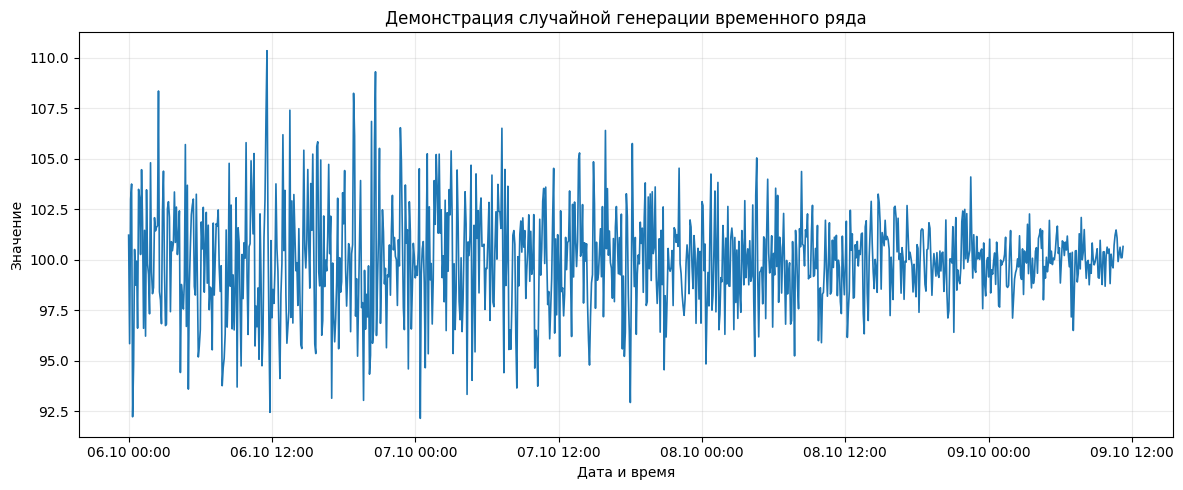


CSV сохранён: ts_20261006_211836.csv
PNG сохранён: ts_demo.png
JSON сохранён: ts_20261006_211836.json


In [11]:
timestamps, values, meta = generate_time_series(
    n_points=1000,
    variance='random',
    trend='random',
    seasonality='random',
    seed=42,
)

print('Параметры сгенерированного ряда:')
for key, value in meta.items():
    if key not in ('outlier_indices', 'missing_indices'):
        print(f'  {key}: {value}')

print('\nПервые 5 точек:')
for ts, value in zip(timestamps[:5], values[:5]):
    print(f'  {ts:%Y-%m-%d %H:%M:%S}  {value:.6f}')

CSV_PATH = save_csv(timestamps, values)
PNG_PATH = ROOT / 'ts_demo.png'
META_PATH = CSV_PATH.with_suffix('.json')
save_plot(timestamps, values, PNG_PATH, 'Демонстрация случайной генерации временного ряда')
meta_for_json = {**meta, 'csv_file': str(CSV_PATH), 'png_file': str(PNG_PATH), 'created_at': datetime.now().isoformat(timespec='seconds')}
save_metadata_json(meta_for_json, META_PATH)
print('\nCSV сохранён:', CSV_PATH)
print('PNG сохранён:', PNG_PATH)
print('JSON сохранён:', META_PATH)

## 4. Примеры вызова опций и три отчётных изображения

generate_time_series(n_points=200, variance='const', trend='none', seasonality='none')
generate_time_series(n_points=200, variance='grow', trend='slow_up', seasonality='one')
generate_time_series(n_points=200, variance='decay', trend='fast_down', seasonality='two')


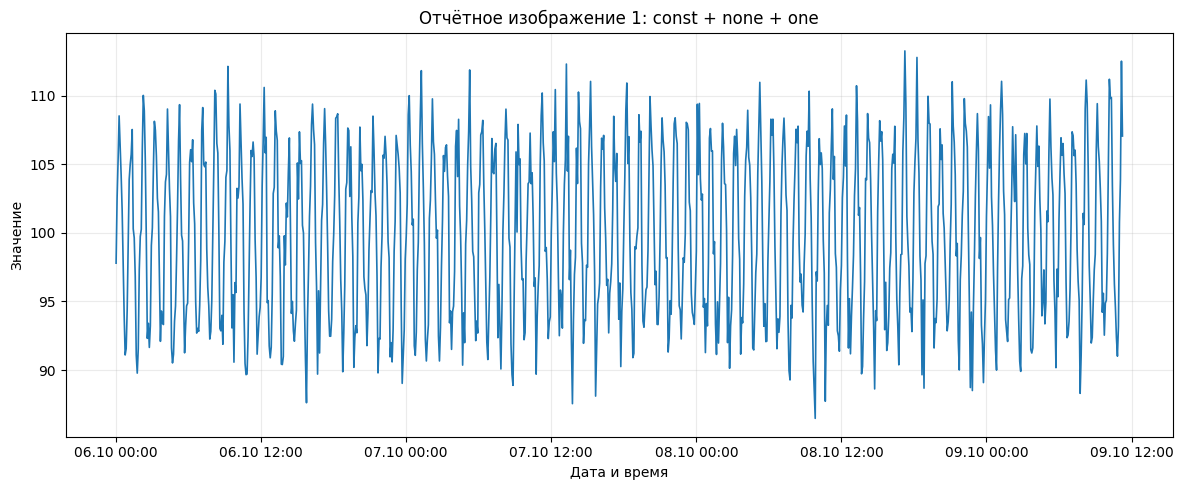

Сохранено: images\lab_image_1.png


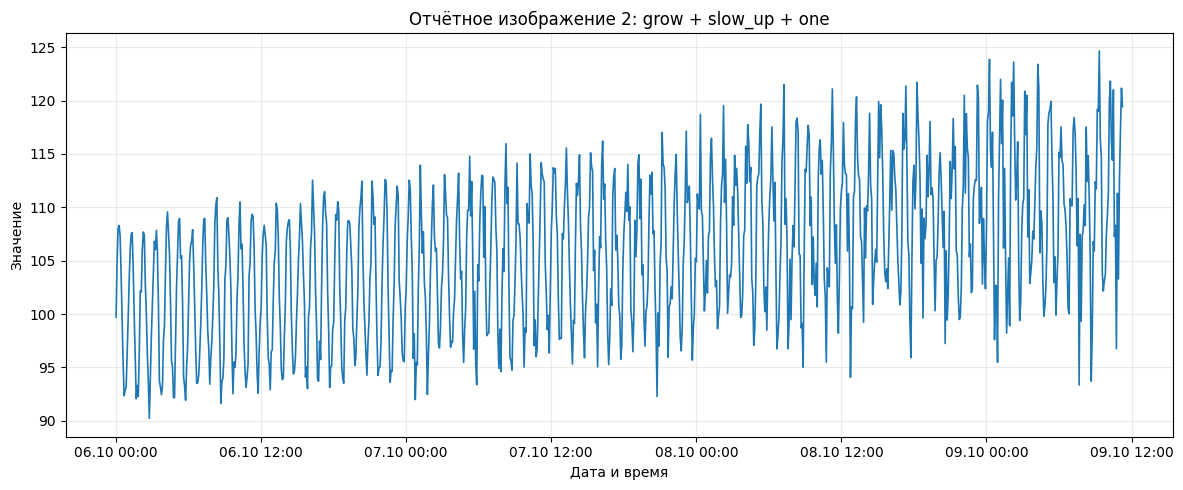

Сохранено: images\lab_image_2.png


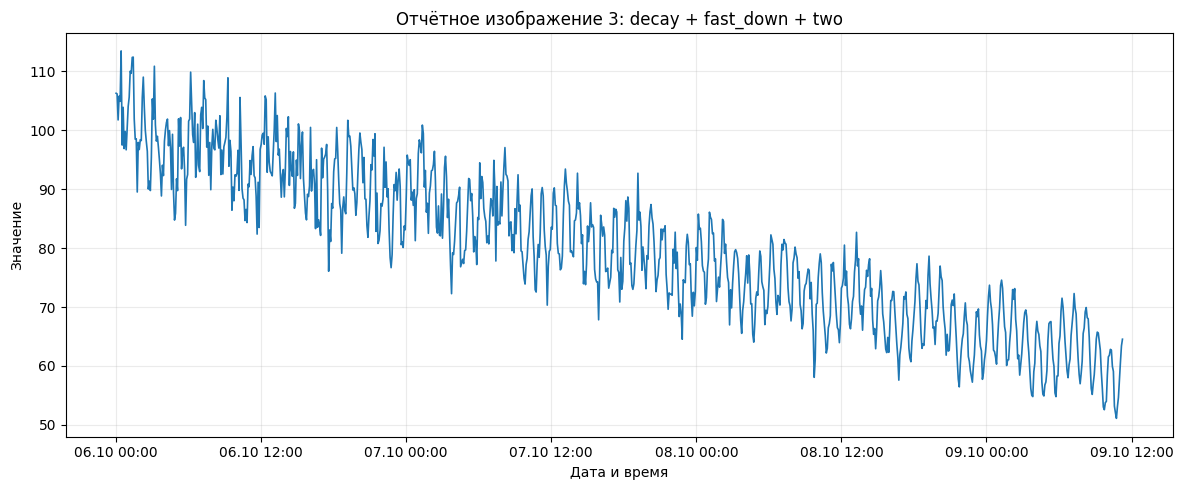

Сохранено: images\lab_image_3.png
Проверка обязательных режимов:
все обязательные режимы выполнены без ошибок


In [12]:
examples = [
    ('const', 'none', 'none'),
    ('grow', 'slow_up', 'one'),
    ('decay', 'fast_down', 'two'),
]
for variance, trend, seasonality in examples:
    generate_time_series(n_points=200, variance=variance, trend=trend, seasonality=seasonality, seed=1)
    print(f"generate_time_series(n_points=200, variance={variance!r}, trend={trend!r}, seasonality={seasonality!r})")

report_cases = [
    ('lab_image_1.png', dict(n_points=1000, variance='const', trend='none', seasonality='one', seed=10), 'Отчётное изображение 1: const + none + one'),
    ('lab_image_2.png', dict(n_points=1000, variance='grow', trend='slow_up', seasonality='one', seed=20), 'Отчётное изображение 2: grow + slow_up + one'),
    ('lab_image_3.png', dict(n_points=1000, variance='decay', trend='fast_down', seasonality='two', seed=30), 'Отчётное изображение 3: decay + fast_down + two'),
]
for filename, params, title in report_cases:
    ts, vals, _ = generate_time_series(**params)
    save_plot(ts, vals, IMAGE_DIR / filename, title)
    print(f'Сохранено: {IMAGE_DIR / filename}')

print('Проверка обязательных режимов:')
for variance in VARIANCE_MODES:
    generate_time_series(n_points=50, variance=variance, trend='none', seasonality='none', seed=1)
for trend in TREND_MODES:
    generate_time_series(n_points=50, variance='const', trend=trend, seasonality='none', seed=1)
for seasonality in SEASONALITY_MODES:
    generate_time_series(n_points=100, variance='const', trend='none', seasonality=seasonality, seed=1)
print('все обязательные режимы выполнены без ошибок')

# 5. Дополнительное задание 1 — нелинейные тренды

Добавлены три нелинейных тренда: **экспоненциальный**, **полиномиальный** и **логарифмический**. Они задаются параметром `nonlinear_trend`.

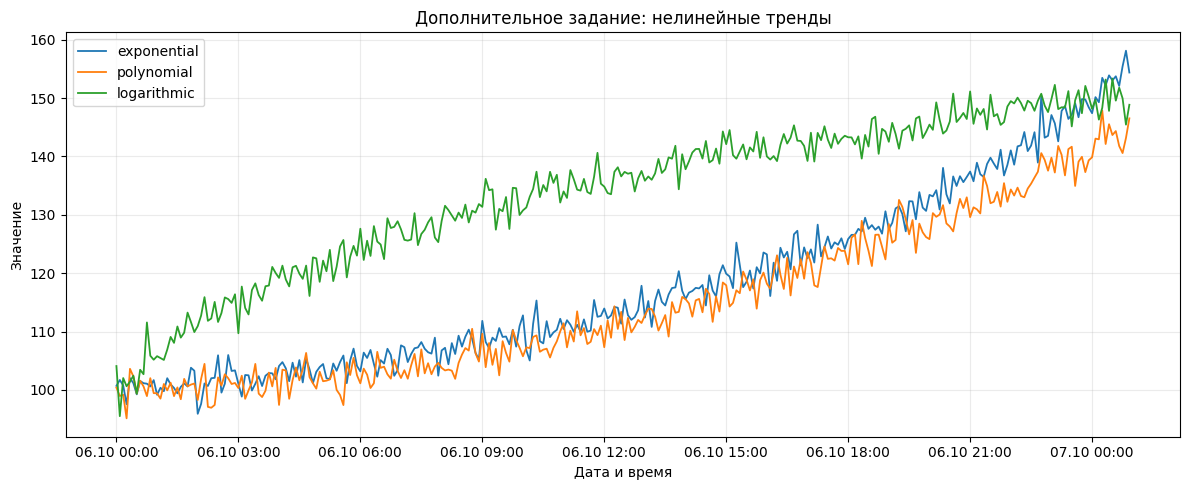

Нелинейные тренды: exponential, polynomial, logarithmic — проверены.
График сохранён: images\lab_extra_nonlinear.png


In [13]:
plt.figure(figsize=(12, 5))
for mode, seed in [('exponential', 1), ('polynomial', 2), ('logarithmic', 3)]:
    ts, vals, _ = generate_time_series(
        n_points=300,
        variance='const',
        trend='none',
        seasonality='none',
        nonlinear_trend=mode,
        seed=seed,
    )
    plt.plot(ts, vals, linewidth=1.3, label=mode)
plt.title('Дополнительное задание: нелинейные тренды')
plt.xlabel('Дата и время')
ax = plt.gca()
ax.xaxis.set_major_locator(mdates.AutoDateLocator(minticks=6, maxticks=10))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%d.%m %H:%M'))
plt.xticks(rotation=0)
plt.ylabel('Значение')
plt.legend()
plt.grid(True, alpha=0.25)
plt.tight_layout()
NONLINEAR_PNG = IMAGE_DIR / 'lab_extra_nonlinear.png'
plt.savefig(NONLINEAR_PNG, dpi=160, bbox_inches='tight')
plt.show()
plt.close()
for mode in NONLINEAR_TREND_MODES[1:]:
    generate_time_series(n_points=50, nonlinear_trend=mode, seed=1)
print('Нелинейные тренды: exponential, polynomial, logarithmic — проверены.')
print('График сохранён:', NONLINEAR_PNG)

# 6. Дополнительное задание 2 — выбросы

Добавлена функция `add_outliers()`. Доля выбросов задаётся параметром `outlier_fraction`. В демонстрации используется 2% точек.

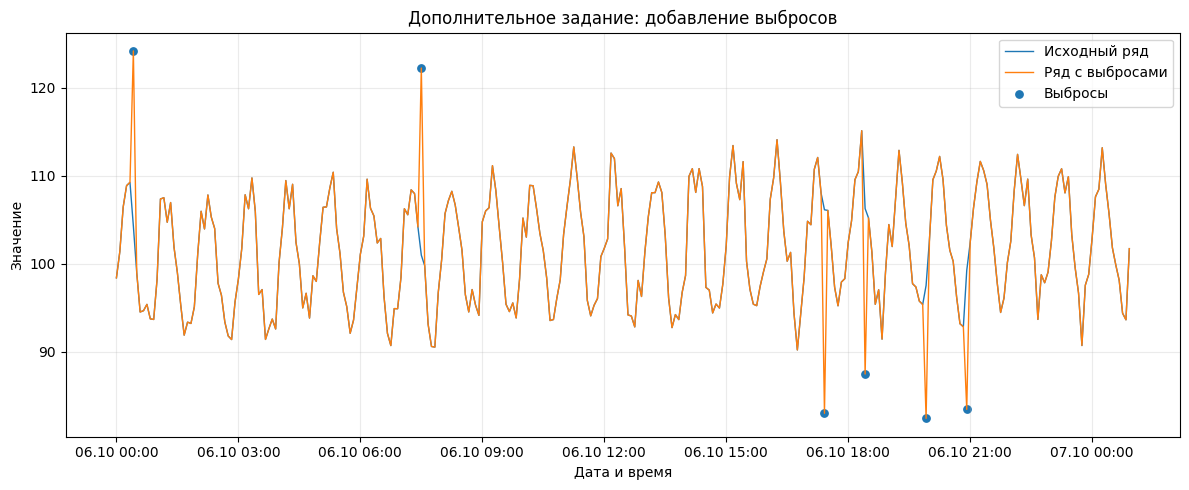

Количество выбросов: 6
Индексы первых выбросов: [5, 90, 209, 221, 239, 251]
График сохранён: images\lab_extra_outliers.png


In [14]:
ts_out, vals_base, _ = generate_time_series(
    n_points=300,
    variance='const',
    trend='slow_up',
    seasonality='one',
    seed=5,
)
vals_out, outlier_indices = add_outliers(vals_base, fraction=0.02, scale=18.0, seed=505)

plt.figure(figsize=(12, 5))
plt.plot(ts_out, vals_base, linewidth=1.0, label='Исходный ряд')
plt.plot(ts_out, vals_out, linewidth=1.0, label='Ряд с выбросами')
if outlier_indices:
    plt.scatter([ts_out[i] for i in outlier_indices], [vals_out[i] for i in outlier_indices], s=28, label='Выбросы')
plt.title('Дополнительное задание: добавление выбросов')
plt.xlabel('Дата и время')
ax = plt.gca()
ax.xaxis.set_major_locator(mdates.AutoDateLocator(minticks=6, maxticks=10))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%d.%m %H:%M'))
plt.xticks(rotation=0)
plt.ylabel('Значение')
plt.legend()
plt.grid(True, alpha=0.25)
plt.tight_layout()
OUTLIERS_PNG = IMAGE_DIR / 'lab_extra_outliers.png'
plt.savefig(OUTLIERS_PNG, dpi=160, bbox_inches='tight')
plt.show()
plt.close()
print('Количество выбросов:', len(outlier_indices))
print('Индексы первых выбросов:', outlier_indices[:10])
print('График сохранён:', OUTLIERS_PNG)

# 7. Дополнительное задание 3 — пропуски

Добавлена функция `add_missing_values()`. Пропущенные значения представлены как `NaN` в Python и как пустые поля `value` в CSV. Временные метки при этом сохраняются.

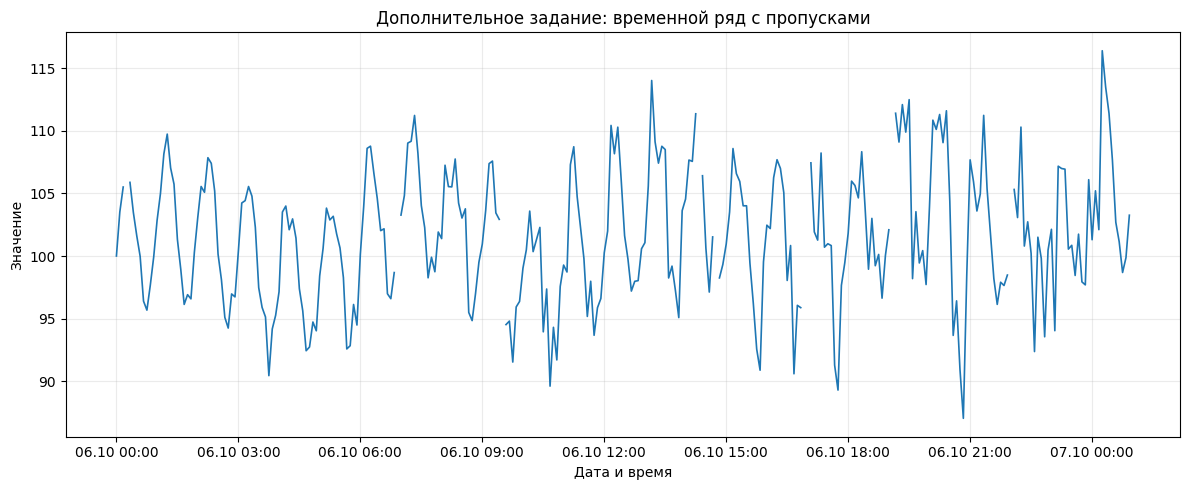

Количество пропусков: 9
Индексы первых пропусков: [3, 83, 114, 172, 177, 203, 204, 229, 264]
График сохранён: images\lab_extra_missing.png


In [15]:
ts_missing, vals_missing, meta_missing = generate_time_series(
    n_points=300,
    variance='grow',
    trend='slow_up',
    seasonality='two',
    missing_fraction=0.03,
    seed=7,
)

plt.figure(figsize=(12, 5))
plt.plot(ts_missing, vals_missing, linewidth=1.2)
plt.title('Дополнительное задание: временной ряд с пропусками')
plt.xlabel('Дата и время')
ax = plt.gca()
ax.xaxis.set_major_locator(mdates.AutoDateLocator(minticks=6, maxticks=10))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%d.%m %H:%M'))
plt.xticks(rotation=0)
plt.ylabel('Значение')
plt.grid(True, alpha=0.25)
plt.tight_layout()
MISSING_PNG = IMAGE_DIR / 'lab_extra_missing.png'
plt.savefig(MISSING_PNG, dpi=160, bbox_inches='tight')
plt.show()
plt.close()
print('Количество пропусков:', int(np.isnan(vals_missing).sum()))
print('Индексы первых пропусков:', meta_missing['missing_indices'][:10])
print('График сохранён:', MISSING_PNG)

# 8. Дополнительное задание 4 — метаданные в JSON

Для генерации с дополнительными параметрами создаётся отдельный JSON-файл. В него включаются количество точек, шаг, время начала, выбранные режимы, seed, количество и индексы выбросов и пропусков, а также имена созданных файлов.

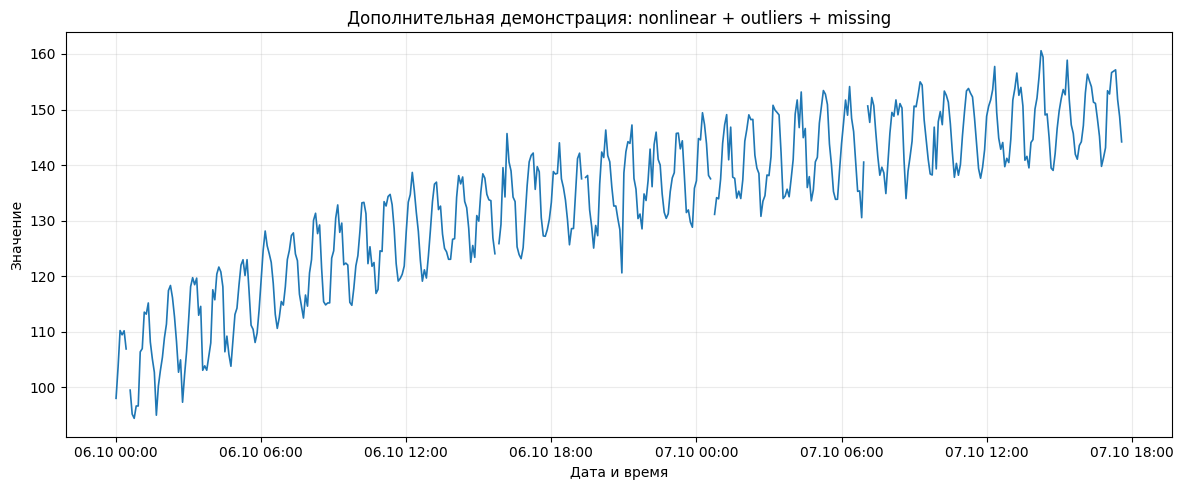

CSV: ts_20261006_211838.csv
PNG: ts_extra_demo.png
JSON: ts_20261006_211838.json
Ключи JSON: ['created_at', 'csv_file', 'interval_minutes', 'missing_count', 'missing_fraction', 'missing_indices', 'n_points', 'nonlinear_trend', 'outlier_count', 'outlier_fraction', 'outlier_indices', 'png_file', 'seasonality', 'seed', 'start', 'trend', 'variance']


In [16]:
extra_ts, extra_values, extra_meta = generate_time_series(
    n_points=500,
    variance='random',
    trend='none',
    seasonality='random',
    nonlinear_trend='logarithmic',
    outlier_fraction=0.02,
    missing_fraction=0.01,
    seed=123,
)

EXTRA_CSV = save_csv(extra_ts, extra_values)
EXTRA_PNG = ROOT / 'ts_extra_demo.png'
save_plot(extra_ts, extra_values, EXTRA_PNG, 'Дополнительная демонстрация: nonlinear + outliers + missing')
extra_meta_for_json = {
    **extra_meta,
    'csv_file': str(EXTRA_CSV),
    'png_file': str(EXTRA_PNG),
    'created_at': datetime.now().isoformat(timespec='seconds'),
}
EXTRA_JSON = EXTRA_CSV.with_suffix('.json')
save_metadata_json(extra_meta_for_json, EXTRA_JSON)

print('CSV:', EXTRA_CSV)
print('PNG:', EXTRA_PNG)
print('JSON:', EXTRA_JSON)
print('Ключи JSON:', sorted(extra_meta_for_json.keys()))

## Заключение

Получен генератор синтетических временных рядов, соответствующий требованиям основной части лабораторной работы. Дополнительно реализованы экспоненциальный, полиномиальный и логарифмический тренды, добавление выбросов, добавление пропусков и сохранение параметров генерации в отдельный JSON-файл.